# Dynamic Clustering

This workbook contains code for clustering and analysis of LiDAR recording. The widget app can be used to select the file to analyse, the clustering method and hyperparameters and evaluate the clustering outcome on a dataset.

In [1]:
%matplotlib widget

from pathlib import Path
import csv
import math
import struct
import time

import dpkt
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import DBSCAN, KMeans, SpectralClustering
import hdbscan

from IPython.display import clear_output, display
import ipywidgets as widgets


## Data preprocessing

Filtering, subsampling

In [2]:

def subsample_points(points, keep_fraction):
    """ Reduce the number of points by subselectiong points evenly throughout dataset"""
    if not 0 < keep_fraction <= 1:
        raise ValueError("keep_fraction must be between 0 and 1")
    keep_count = max(1, int(len(points) * keep_fraction))
    indices = np.linspace(0, len(points) - 1, keep_count, dtype=int)
    return points[indices]


In [3]:

def filter(points, min_distance, max_distance):
    """ Reduce number of points by distance from sensor"""
    distances = np.linalg.norm(points, axis=1)
    filtered = points[(distances >= min_distance) & (distances <= max_distance)]
    return filtered


In [4]:
def prepare_frame_points(points, min_distance, max_distance, keep_fraction):
    # Reduce number of points analysed to improve computation time
    filtered = filter(points, min_distance, max_distance)

    # If points remain after filtering, evenly subsample
    if len(filtered) and keep_fraction < 1.0: 
        filtered = subsample_points(points, keep_fraction)
    return filtered


## Clustering

In [5]:
# Despite only DBSCAN being used for project analysis, all clustering algorithms 
# are present in the app to allow for future comparison if required by user

def cluster_points(points, method, cluster_count, dbscan_eps, min_samples, hdbscan_min_cluster_size, spectral_neighbors):
    # Cluster points with specified method and parameters
    point_count = len(points)
    if point_count == 0: # Return if there are no points to cluster
        return np.empty(0, dtype=int)
    if method == 'K-means':
        return KMeans(n_clusters=min(cluster_count, point_count), n_init=10, random_state=42).fit_predict(points)
    if method == 'Spectral':
        if point_count < 2:
            return np.zeros(point_count, dtype=int)
        count = min(cluster_count, point_count - 1)
        neighbors = min(spectral_neighbors, point_count - 1)
        return SpectralClustering(n_clusters=count, affinity='nearest_neighbors', n_neighbors=neighbors, assign_labels='kmeans', random_state=42).fit_predict(points)
    if method == 'DBSCAN':
        return DBSCAN(eps=dbscan_eps, min_samples=min_samples).fit_predict(points)
    if method == 'HDBSCAN':
        if point_count < 2:
            return np.full(point_count, -1, dtype=int)
        return hdbscan.HDBSCAN(min_cluster_size=min(hdbscan_min_cluster_size, point_count), min_samples=min_samples).fit_predict(points)
    raise ValueError(f'Unknown clustering method: {method}')


def cluster_frame(points, method, settings, seed):
    selected, plane_removal = prepare_frame_points(
        points,
        settings['min_distance'],
        settings['max_distance'],
        settings['keep_fraction'],
        settings.get('box_filter'),
    )
    labels = cluster_points(selected, method, settings['cluster_count'], settings['dbscan_eps'], settings['min_samples'], settings['hdbscan_min_cluster_size'], settings['spectral_neighbors'])
    cluster_labels = set(labels.tolist()) - {-1}
    return {
        'points': selected,
        'labels': labels,
        'decoded_count': len(points),
        'used_count': len(selected),
        'cluster_count': len(cluster_labels),
        'noise_count': int(np.count_nonzero(labels == -1)),
        'plane_removal': plane_removal,
    }

## Open file

File path and angle correction path are hard coded instead of relying on upload widget because the dimentions of the bounding box are later harrd coded also within the analysis. 

To decode the .pcap file, the correct angle_correction file must be specified. The Hestai JT128 angle correction file can be downloaded from https://www.hesaitech.com/product_downloads/jt128/

Load file and decode using angle correction for JT128 sensor.

In [6]:

def load_calibration(path):
    """Load JT128 per-channel elevation and azimuth calibration angles."""
    calibration = {}
    with path.open("r", encoding="utf-8", errors="ignore", newline="") as calibration_file:
        # DictReader maps each CSV row by its column names
        for row in csv.DictReader(calibration_file):
            try:
                channel = int(row["Channel"])
                elevation = float(row["Elevation"])
                azimuth = float(row["Azimuth"])
            except (KeyError, TypeError, ValueError):
                # Ignore incomplete rows and values that cannot be parsed
                continue
            calibration[channel] = (elevation, azimuth)

    # Require exactly the expected channel IDs before building indexed arrays
    if sorted(calibration) != list(range(1, 129)):
        raise ValueError(f"Expected 128 JT128 calibration rows in {path}.")

    # Keep both arrays in channel order so packet channel indices align with them
    elevations = np.array([calibration[channel][0] for channel in range(1, 129)], dtype=float)
    azimuth_offsets = np.array([calibration[channel][1] for channel in range(1, 129)], dtype=float)
    return elevations, azimuth_offsets

In [7]:

def decode_packet(payload):
    """Decode one JT128 v1.4 UDP payload into azimuth-tagged point blocks."""
    # Ignore payloads that are too short to contain the header or use another format
    if len(payload) < 12 or payload[:4] != b"\xee\xff\x01\x04":
        return []

    # Read channel count, block count, distance unit, and feature flags from the header
    laser_count, block_count, _, distance_unit_mm, _, status = payload[6:12]
    # Calibration is indexed per laser, so its channel count must match the packet
    if laser_count != len(VERTICAL_ANGLES_DEG):
        raise ValueError(f"Packet has {laser_count} channels, but the calibration has {len(VERTICAL_ANGLES_DEG)}.")

    # Each laser record has a base size plus optional fields indicated by status bits
    unit_size = 3 + bool(status & 0x10) + bool(status & 0x20) + bool(status & 0x40)
    block_size = 2 + laser_count * unit_size
    # Include every optional packet tail when checking the exact expected payload size.
    optional_size = 4  # CRC following the block data
    optional_size += 17 if status & 0x04 else 0  # Function-safety data
    optional_size += 26  # Hesai packet tail
    optional_size += 4 if status & 0x01 else 0  # Sequence number
    optional_size += 22 if status & 0x02 else 0  # IMU data
    optional_size += 4  # Packet CRC
    optional_size += 32 if status & 0x08 else 0  # Cyber-security signature
    expected_size = 12 + block_count * block_size + optional_size
    if len(payload) != expected_size:
        raise ValueError(f"Unexpected Hesai v1.4 payload size {len(payload)}; expected {expected_size}.")

    distance_unit_m = distance_unit_mm / 1000.0
    decoded_blocks = []
    block_offset = 12
    # Decode each block's rotation angle and one distance record per laser channel.
    for _ in range(block_count):
        azimuth_deg = int.from_bytes(payload[block_offset:block_offset + 2], "little") / 100.0
        block_offset += 2
        azimuths = np.radians((azimuth_deg + AZIMUTH_OFFSETS_DEG) % 360.0)
        elevations = np.radians(VERTICAL_ANGLES_DEG)
        distances = np.empty(laser_count, dtype=float)

        for channel in range(laser_count):
            record = payload[block_offset:block_offset + unit_size]
            raw_distance = struct.unpack_from("<H", record)[0]
            distances[channel] = raw_distance * distance_unit_m
            block_offset += unit_size

        # Convert calibrated spherical measurements into Cartesian XYZ coordinates.
        horizontal = distances * np.cos(elevations)
        points = np.column_stack((
            horizontal * np.sin(azimuths),
            horizontal * np.cos(azimuths),
            distances * np.sin(elevations),
        ))
        # Zero distance marks a channel with no return; omit those points.
        points = points[distances > 0]
        decoded_blocks.append((azimuth_deg, points))

    return decoded_blocks



In [8]:
# File to analyse 
PCAP_PATH = Path("../data/driveway.pcap")

# Angle correction file used by Jt128 sensor
CALIBRATION_PATH = Path("../Lidar setup/JT128_angle_correction.csv")

# Frames to work with while clustering
FIRST_FRAME = 5
LAST_FRAMES = 90


In [9]:
# Load angles from the correction file
VERTICAL_ANGLES_DEG, AZIMUTH_OFFSETS_DEG = load_calibration(CALIBRATION_PATH)

# Load data file and decode using angle corrections
frames = []
frame_blocks = []
previous_azimuth = None

with PCAP_PATH.open("rb") as capture_file:
    reader = dpkt.pcap.Reader(capture_file)
    if reader.datalink() != dpkt.pcap.DLT_EN10MB:
        raise ValueError("Expected an Ethernet .pcap capture.")

    for _, raw_packet in reader:
        try:
            ethernet = dpkt.ethernet.Ethernet(raw_packet)
            network = ethernet.data
            if isinstance(network, dpkt.ip.IP):
                transport = network.data
            elif isinstance(network, dpkt.ip6.IP6):
                transport = network.data
            else:
                continue
            if not isinstance(transport, dpkt.udp.UDP):
                continue
            decoded_blocks = decode_packet(bytes(transport.data))
        except (AttributeError, dpkt.dpkt.NeedData, ValueError):
            continue

        for azimuth, points in decoded_blocks:
            if previous_azimuth is not None and previous_azimuth - azimuth > 180:
                if frame_blocks:
                    frames.append(np.vstack(frame_blocks))
                    frame_blocks = []
                if len(frames) >= LAST_FRAMES:
                    break
            if len(points):
                frame_blocks.append(points)
            previous_azimuth = azimuth

        if len(frames) >= LAST_FRAMES:
            break

# Save required frames for further analysis
if len(frames) < LAST_FRAMES and frame_blocks:
    frames.append(np.vstack(frame_blocks))
if not frames:
    raise ValueError("No valid Hesai protocol v1.4 LiDAR frames found in the capture.")

# Log
first_frame = FIRST_FRAME
print(f"Loaded {len(frames)} frame(s) (From {FIRST_FRAME} to {LAST_FRAMES}) from {PCAP_PATH.resolve()}")
print("Points per frame: " + ", ".join(f"{len(frame):,}" for frame in frames))

Loaded 90 frame(s) (From 5 to 90) from C:\Users\danag\Documents\LIDAR\data\driveway.pcap
Points per frame: 65,038, 98,062, 98,074, 98,063, 98,029, 98,170, 98,560, 98,870, 99,626, 100,016, 100,889, 100,702, 101,105, 101,875, 103,470, 104,938, 106,402, 106,764, 107,443, 107,744, 107,417, 107,620, 107,576, 107,671, 107,446, 108,587, 110,540, 110,879, 110,577, 109,734, 110,936, 111,893, 109,822, 109,492, 107,165, 104,982, 105,967, 105,908, 105,230, 104,691, 104,493, 103,875, 103,255, 102,618, 101,848, 101,318, 100,927, 100,576, 100,404, 99,986, 99,559, 99,343, 95,082, 99,146, 98,818, 98,621, 98,463, 98,280, 98,385, 98,409, 98,211, 98,341, 98,176, 98,193, 98,056, 98,044, 97,904, 97,901, 97,809, 98,121, 98,082, 97,932, 97,955, 97,815, 97,998, 97,826, 98,042, 97,917, 97,912, 97,932, 97,921, 97,863, 98,032, 97,889, 97,791, 98,011, 97,889, 97,698, 97,738, 97,850


## Analyse frames in sequence

For each frame keep only points within a max distance of 15m, remove planes (fall, floor), and cluster.
For each cluster find the centroid. Track objects using the assumption that each cluster is an object and the object is the same as the object in the frevious frame with the nearest centroid.

## Set up widgets

In [ ]:
from IPython.display import clear_output, display
import ipywidgets as widgets

PLOT_MIN_DISTANCE_M = 0.0
PLOT_MAX_DISTANCE_M = 15.0
PLOT_KEEP_FRACTION = 0.8


method_widget = widgets.Dropdown(
    options=["K-means", "DBSCAN", "HDBSCAN", "Spectral"],
    value="DBSCAN",
    description="Method",
)
frame_count_widget = widgets.IntSlider(
    value=min(LAST_FRAMES, len(frames)),
    min=FIRST_FRAME,
    max=LAST_FRAMES,
    step=1,
    description="Frames",
    continuous_update=False,
)
min_distance_widget = widgets.FloatText(value=PLOT_MIN_DISTANCE_M, description="Min range (m)")
max_distance_widget = widgets.FloatText(value=PLOT_MAX_DISTANCE_M, description="Max range (m)")
keep_fraction_widget = widgets.FloatSlider(
    value=PLOT_KEEP_FRACTION,
    min=0.05,
    max=1.0,
    step=0.05,
    description="Point fraction",
    readout_format=".2f",
    continuous_update=False,
)
cluster_count_widget = widgets.IntSlider(
    value=5,
    min=2,
    max=30,
    step=1,
    description="K-means/Spectral clusters",
    continuous_update=False,
)
dbscan_eps_widget = widgets.FloatText(value=0.1, description="DBSCAN eps (m)")
min_samples_widget = widgets.IntSlider(
    value=10,
    min=1,
    max=100,
    step=1,
    description="Min samples",
    continuous_update=False,
)
hdbscan_min_cluster_size_widget = widgets.IntSlider(
    value=10,
    min=2,
    max=100,
    description="HDBSCAN min cluster size",
    continuous_update=False,
)
spectral_neighbors_widget = widgets.IntSlider(
    value=10,
    min=1,
    max=100,
    step=1,
    description="Spectral neighbors",
    continuous_update=False,
)

association_gate_widget = widgets.FloatText(
    value=0.75, description="Match gate (m)"
)


# Default bounding box includes all points in scene
#scene_minimum = np.min([frame.min(axis=0) for frame in frames], axis=0)
#scene_maximum = np.max([frame.max(axis=0) for frame in frames], axis=0)
#default_vertices = [
#    (scene_minimum[0], scene_minimum[1]),
#    (scene_maximum[0], scene_minimum[1]),
#    (scene_maximum[0], scene_maximum[1]),
#    (scene_minimum[0], scene_maximum[1]),
#]


# Default vertices set to vertices used for Outdoor data bounding box
default_vertices = [
    (-3, -3),
    (-0.5,-5),
    (-5,-8.5),
    (-6,-7),
]

bbox_vertex_widgets = [
    (
        widgets.FloatText(value=float(x), description=f"V{index} X (m)"),
        widgets.FloatText(value=float(y), description=f"V{index} Y (m)"),
    )
    for index, (x, y) in enumerate(default_vertices, start=1)
]
#bbox_zmin_widget = widgets.FloatText(value=float(scene_minimum[2]), description="Z min (m)")
#bbox_zmax_widget = widgets.FloatText(value=float(scene_maximum[2]), description="Z max (m)")

bbox_zmin_widget = widgets.FloatText(value=0, description="Z min (m)")
bbox_zmax_widget = widgets.FloatText(value=3, description="Z max (m)")
manual_box_controls = widgets.VBox([
    widgets.HTML("<b>Manual bounding-box footprint</b>"),
    widgets.HTML("Enter vertices V1-V4 in clockwise or counter-clockwise order."),
    *(widgets.HBox(vertex) for vertex in bbox_vertex_widgets),
    widgets.HBox([bbox_zmin_widget, bbox_zmax_widget]),
])
run_button = widgets.Button(description="Cluster and plot", button_style="primary", icon="play")
plot_output = widgets.Output()

controls = widgets.VBox([
    widgets.HBox([method_widget, frame_count_widget]),
    widgets.HBox([min_distance_widget, max_distance_widget, keep_fraction_widget]),
    widgets.HBox([cluster_count_widget, dbscan_eps_widget, min_samples_widget]),
    widgets.HBox([
        hdbscan_min_cluster_size_widget,
        spectral_neighbors_widget,
        association_gate_widget,
    ]),
])



## Define box(es)

Manually defined bounding boxes establish ground truth data and allow for evaluation of clustering algorithms compared to manually defined object locations. THe box is constant throughout the recording, and cannot be changed on a frame by frame basis

In [11]:
# Unlike the single frame clustering apps, bounding box can be of an 
# arbitrary shape defined by 4 x/y plane vertices and a min/max height in the z axis.

def validate_box(box, description):
    # Ensure box specified by the user is valid. Points must be specified in clockwise or ounter clockwise direction.
    vertices = np.asarray(box["vertices"], dtype=float)
    z_min = float(box["zmin"])
    z_max = float(box["zmax"])
    if vertices.shape != (4, 2) or not np.all(np.isfinite(vertices)):
        raise ValueError(f"{description} must have four finite X/Y vertices.")
    if not np.isfinite(z_min) or not np.isfinite(z_max) or z_min > z_max:
        raise ValueError(f"{description} Z min must be less than or equal to Z max.")
    if len(np.unique(vertices, axis=0)) != 4:
        raise ValueError(f"{description} vertices must be distinct and entered around the perimeter.")
    signed_area = 0.5 * np.sum(
        vertices[:, 0] * np.roll(vertices[:, 1], -1)
        - vertices[:, 1] * np.roll(vertices[:, 0], -1)
    )
    if abs(signed_area) <= 1e-12:
        raise ValueError(f"{description} vertices must enclose a non-zero area.")

    def orientation(a, b, c):
        return (b[0] - a[0]) * (c[1] - a[1]) - (b[1] - a[1]) * (c[0] - a[0])

    def on_segment(a, b, point):
        return (
            min(a[0], b[0]) - 1e-12 <= point[0] <= max(a[0], b[0]) + 1e-12
            and min(a[1], b[1]) - 1e-12 <= point[1] <= max(a[1], b[1]) + 1e-12
        )

    def segments_intersect(a, b, c, d):
        o1, o2 = orientation(a, b, c), orientation(a, b, d)
        o3, o4 = orientation(c, d, a), orientation(c, d, b)
        if ((o1 > 1e-12 and o2 < -1e-12) or (o1 < -1e-12 and o2 > 1e-12)) and (
            (o3 > 1e-12 and o4 < -1e-12) or (o3 < -1e-12 and o4 > 1e-12)
        ):
            return True
        return (
            (abs(o1) <= 1e-12 and on_segment(a, b, c))
            or (abs(o2) <= 1e-12 and on_segment(a, b, d))
            or (abs(o3) <= 1e-12 and on_segment(c, d, a))
            or (abs(o4) <= 1e-12 and on_segment(c, d, b))
        )

    if segments_intersect(vertices[0], vertices[1], vertices[2], vertices[3]) or segments_intersect(
        vertices[1], vertices[2], vertices[3], vertices[0]
    ):
        raise ValueError(f"{description} vertices must follow the perimeter without crossing.")
    return {"vertices": vertices, "zmin": z_min, "zmax": z_max}


def box_mask(points, box):
    points = np.asarray(points)
    vertices = np.asarray(box["vertices"], dtype=float)
    inside_xy = np.zeros(len(points), dtype=bool)
    x = points[:, 0]
    y = points[:, 1]
    for start, end in zip(vertices, np.roll(vertices, -1, axis=0)):
        x1, y1 = start
        x2, y2 = end
        cross = (x - x1) * (y2 - y1) - (y - y1) * (x2 - x1)
        on_edge = (
            (np.abs(cross) <= 1e-9)
            & (x >= min(x1, x2) - 1e-9)
            & (x <= max(x1, x2) + 1e-9)
            & (y >= min(y1, y2) - 1e-9)
            & (y <= max(y1, y2) + 1e-9)
        )
        if y1 != y2:
            crosses_ray = ((y1 > y) != (y2 > y)) & (
                x < (x2 - x1) * (y - y1) / (y2 - y1) + x1
            )
            inside_xy ^= crosses_ray
        inside_xy |= on_edge
    inside_z = (points[:, 2] >= box["zmin"]) & (points[:, 2] <= box["zmax"])
    return inside_xy & inside_z


def get_manual_box():
    box = {
        "vertices": [(x.value, y.value) for x, y in bbox_vertex_widgets],
        "zmin": bbox_zmin_widget.value,
        "zmax": bbox_zmax_widget.value,
    }
    return validate_box(box, "Manual box")


def best_cluster_for_box(labels, manual_mask):
    candidates = [label for label in np.unique(labels) if label != -1]
    if not candidates:
        candidates = list(np.unique(labels))

    best = None
    for label in candidates:
        predicted = labels == label
        true_positive = int(np.count_nonzero(predicted & manual_mask))
        false_positive = int(np.count_nonzero(predicted & ~manual_mask))
        false_negative = int(np.count_nonzero(~predicted & manual_mask))
        precision = true_positive / max(true_positive + false_positive, 1)
        recall = true_positive / max(true_positive + false_negative, 1)
        f1 = 2 * precision * recall / max(precision + recall, 1e-12)
        candidate = {
            "label": label,
            "mask": predicted,
            "precision": precision,
            "recall": recall,
            "f1": f1,
        }
        if best is None or candidate["f1"] > best["f1"]:
            best = candidate
    return best



In [12]:

def draw_box_edges(axes, box):
    vertices = np.asarray(box["vertices"], dtype=float)
    closed_vertices = np.vstack([vertices, vertices[0]])
    for z_value in (box["zmin"], box["zmax"]):
        axes.plot(
            closed_vertices[:, 0],
            closed_vertices[:, 1],
            np.full(len(closed_vertices), z_value),
            color="blue",
            linewidth=1,
        )
    for x_value, y_value in vertices:
        axes.plot([x_value, x_value], [y_value, y_value], [box["zmin"], box["zmax"]], color="blue", linewidth=1)



# Plot frames for validation

Display a given frame from the uploaded data to check bounding boxes and data contained in frame

In [13]:

single_frame_widget = widgets.IntSlider(
    value=1,
    min=1,
    max=len(frames),
    step=1,
    description="Frame",
    continuous_update=False,
)
single_frame_button = widgets.Button(description="Show frame", button_style="primary", icon="eye")
single_frame_output = widgets.Output()



def plot_single_frame(_):
    single_frame_button.disabled = True
    try:
        frame_number = single_frame_widget.value
        frame = frames[frame_number - 1]
        points_to_plot = prepare_frame_points(
            frame,
            min_distance=min_distance_widget.value,
            max_distance=max_distance_widget.value,
            keep_fraction=keep_fraction_widget.value,
        )

        if not len(points_to_plot):
            raise ValueError("No points remain after applying the current distance and sampling settings.")

        box = get_manual_box()

        inside_box = box_mask(points_to_plot, box)
        inside_points = points_to_plot[inside_box]
        outside_points = points_to_plot[~inside_box]
        

        with single_frame_output:
            clear_output(wait=True)
            figure = plt.figure(figsize=(10, 8))
            axes = figure.add_subplot(111, projection="3d")
            if len(outside_points):
                axes.scatter(*outside_points.T, c="lightgray", s=1, alpha=0.3, label="Outside box")
            if len(inside_points):
                axes.scatter(*inside_points.T, c="crimson", s=3, alpha=0.9, label="Inside box")
            draw_box_edges(axes, box)
            axes.set_title(f"Frame {frame_number}: {len(points_to_plot):,} points, {int(inside_box.sum()):,} inside box")
            axes.set_xlabel("X (m)")
            axes.set_ylabel("Y (m)")
            axes.set_zlabel("Z (m)")
            axes.set_box_aspect(np.maximum(np.ptp(points_to_plot, axis=0), 1e-6))
            axes.legend(loc="upper right")
            plt.tight_layout()
            plt.show()
    except Exception as error:
        with single_frame_output:
            clear_output(wait=True)
            print(f"Frame preview failed: {error}")
    finally:
        single_frame_button.disabled = False


single_frame_button.on_click(plot_single_frame)
plot_single_frame(None)
display(
    widgets.HBox([
        widgets.VBox([single_frame_widget, single_frame_button]),
        manual_box_controls,
    ]),
    single_frame_output,
)

Output()

## Find centroids and match centroids between frames to establish object continuity

In [14]:

def match_cluster_centroids(points, labels, previous_centroids, association_gate, next_track_id):
    centroids = {
        label: points[labels == label].mean(axis=0)
        for label in np.unique(labels)
        if label != -1 and np.any(labels == label)
    }
    candidate_pairs = sorted(
        (
            float(np.linalg.norm(previous_position - centroids[label])),
            track_id,
            label,
        )
        for track_id, previous_position in previous_centroids.items()
        for label in centroids
    )
    assignments = {}
    used_tracks = set()
    for distance, track_id, label in candidate_pairs:
        if distance <= association_gate and track_id not in used_tracks and label not in assignments:
            assignments[label] = track_id
            used_tracks.add(track_id)

    current_centroids = {}
    for label, centroid in centroids.items():
        if label not in assignments:
            assignments[label] = next_track_id
            next_track_id += 1
        current_centroids[assignments[label]] = centroid.copy()
    return centroids, assignments, current_centroids, next_track_id



## Plotting and formatting

In [15]:

def _render_selected_frame_results(
    frame_numbers,
    frame_results,
    frame_messages,
    best_cluster_motion_rows,
    centroid_tracks,
):
    with plot_output:
        clear_output(wait=True)
        results_by_frame = {result["frame"]: result for result in frame_results}
        messages_by_frame = dict(frame_messages)
        for frame_number in frame_numbers:
            if frame_number in messages_by_frame:
                print(messages_by_frame[frame_number])
                continue
            result = results_by_frame[frame_number]
            print(
                f"Frame {frame_number}/{len(frame_numbers)}: "
                f"{result['point_count']:,} points, {result['cluster_count']} clusters, "
                f"{result['noise_count']:,} noise points, best label {result['label']}, "
                f"precision {result['precision']:.3f}, recall {result['recall']:.3f}, "
                f"F1 {result['f1']:.3f}"
            )

        motion_headers = [
            "Frame", "Cluster label", "Track ID", "Centroid X (m)",
            "Centroid Y (m)", "Centroid Z (m)", "Delta X (m/frame)",
            "Delta Y (m/frame)", "Delta Z (m/frame)",
            "Motion (m/frame)", "Box-match F1",
        ]
        motion_table = "<h4>Best cluster motion by frame</h4><table><tr>" + "".join(
            f"<th style='padding:4px 8px'>{header}</th>" for header in motion_headers
        ) + "</tr>"
        for row in best_cluster_motion_rows:
            if row["centroid"] is None:
                values = [
                    row["frame"], "No matched cluster", "-", "-", "-", "-",
                    "-", "-", "-", "-", f"{row['f1']:.3f}",
                ]
            else:
                centroid = row["centroid"]
                displacement = row["displacement"]
                values = [
                    row["frame"], row["label"], row["track_id"],
                    *(f"{value:.3f}" for value in centroid),
                    *(f"{value:.3f}" if np.isfinite(value) else "-" for value in displacement),
                    f"{np.linalg.norm(displacement):.3f}"
                    if np.all(np.isfinite(displacement)) else "-",
                    f"{row['f1']:.3f}",
                ]
            motion_table += "<tr>" + "".join(
                f"<td style='padding:4px 8px'>{value}</td>" for value in values
            ) + "</tr>"
        motion_table += "</table>"
        display(widgets.HTML(value=motion_table))

        object_count = len(centroid_tracks)
        average_lifespan_frames = (
            float(np.mean([len(observations) for observations in centroid_tracks.values()]))
            if centroid_tracks else 0.0
        )
        tracking_summary = (
            "<h4>Object tracking summary</h4><table>"
            "<tr><th style='padding:4px 8px'>Objects identified</th>"
            "<th style='padding:4px 8px'>Average observed lifespan (frames)</th></tr>"
            f"<tr><td style='padding:4px 8px'>{object_count}</td>"
            f"<td style='padding:4px 8px'>{average_lifespan_frames:.2f}</td></tr>"
            "</table>"
            "<p>Lifespan is counted as the number of frames in which each track "
            "has a detected cluster centroid.</p>"
        )
        display(widgets.HTML(value=tracking_summary))

        if not centroid_tracks:
            print("No cluster centroids were available to track.")



def _render_clustering_error(error):
    with plot_output:
        print(f"Clustering failed: {error}")


In [16]:


def cluster_selected_frames(_):
    run_button.disabled = True
    try:
        box = get_manual_box()
        association_gate = association_gate_widget.value
        if association_gate <= 0:
            raise ValueError("The centroid matching gate must be positive.")
        with plot_output:
            clear_output(wait=True)
            selected_frames = frames[:frame_count_widget.value]
            frame_numbers = []
            frame_results = []
            frame_messages = []
            previous_centroids = {}
            next_track_id = 1
            centroid_tracks = {}
            best_cluster_motion_rows = []


            for frame_number, frame in enumerate(selected_frames, start=1):
                plot_points = prepare_frame_points(
                    frame,
                    min_distance=min_distance_widget.value,
                    max_distance=max_distance_widget.value,
                    keep_fraction=keep_fraction_widget.value,
                )

                if not len(plot_points):
                    frame_messages.append((
                        frame_number,
                        f"Frame {frame_number}/{len(selected_frames)}: "
                        "no points remain after filtering; F1 = 0.000",
                    ))
                    frame_numbers.append(frame_number)
                    best_cluster_motion_rows.append({
                        "frame": frame_number,
                        "label": None,
                        "track_id": None,
                        "centroid": None,
                        "displacement": None,
                        "f1": 0.0,
                    })
                    previous_centroids = {}
                    continue

                labels = cluster_points(
                    plot_points,
                    method_widget.value,
                    cluster_count_widget.value,
                    dbscan_eps_widget.value,
                    min_samples_widget.value,
                    hdbscan_min_cluster_size_widget.value,
                    spectral_neighbors_widget.value,
                )
                centroids, track_assignments, current_centroids, next_track_id = match_cluster_centroids(
                    plot_points,
                    labels,
                    previous_centroids,
                    association_gate,
                    next_track_id,
                )
                track_shifts = {}
                track_displacements = {}
                for label, centroid in centroids.items():
                    track_id = track_assignments[label]
                    previous_position = previous_centroids.get(track_id)
                    displacement = (
                        centroid - previous_position
                        if previous_position is not None else np.full(3, np.nan)
                    )
                    shift = float(np.linalg.norm(displacement))
                    track_shifts[label] = shift
                    track_displacements[label] = displacement
                    centroid_tracks.setdefault(track_id, []).append({
                        "frame": frame_number,
                        "position": centroid.copy(),
                        "shift": shift,
                    })
                previous_centroids = current_centroids

                manual_mask = box_mask(plot_points, box)
                best = best_cluster_for_box(labels, manual_mask)
                if best is None:
                    frame_f1 = 0.0
                    frame_messages.append((
                        frame_number,
                        f"Frame {frame_number}/{len(selected_frames)}: "
                        "clustering returned no labels; F1 = 0.000",
                    ))
                    frame_numbers.append(frame_number)
                    best_cluster_motion_rows.append({
                        "frame": frame_number,
                        "label": None,
                        "track_id": None,
                        "centroid": None,
                        "displacement": None,
                        "f1": frame_f1,
                    })
                    continue

                frame_f1 = best["f1"]
                frame_numbers.append(frame_number)
                best_label = best["label"]
                best_cluster_motion_rows.append({
                    "frame": frame_number,
                    "label": int(best_label),
                    "track_id": track_assignments.get(best_label),
                    "centroid": centroids.get(best_label),
                    "displacement": track_displacements.get(best_label),
                    "f1": frame_f1,
                })
                cluster_count = len(set(labels.tolist()) - {-1})
                noise_count = int(np.count_nonzero(labels == -1))
                frame_results.append({
                    "frame": frame_number,
                    "point_count": len(plot_points),
                    "cluster_count": cluster_count,
                    "noise_count": noise_count,
                    "label": int(best_label),
                    "precision": best["precision"],
                    "recall": best["recall"],
                    "f1": frame_f1,
                })

        _render_selected_frame_results(
            frame_numbers,
            frame_results,
            frame_messages,
            best_cluster_motion_rows,
            centroid_tracks,
        )
    except Exception as error:
        _render_clustering_error(error)
    finally:
        run_button.disabled = False



In [ ]:

run_button.on_click(cluster_selected_frames)
display(controls, run_button, plot_output)

cluster_selected_frames() # call function immediately with default values

Button(button_style='primary', description='Cluster and plot', icon='play', style=ButtonStyle())

Output()

# Plot position of best cluster centroid at each frame

Show the movement of the tracked object over time

In [18]:

def plot_centroid_by_frame():
    frame_numbers = []
    centroids_by_frame = []

    box = get_manual_box()

    for frame_number, frame in enumerate(frames[:frame_count_widget.value], start=1):
        plot_points = prepare_frame_points(
            frame,
            min_distance_widget.value,
            max_distance_widget.value,
            keep_fraction_widget.value,
        )

        if not len(plot_points):
            continue

        labels = cluster_points(
            plot_points,
            method_widget.value,
            cluster_count_widget.value,
            dbscan_eps_widget.value,
            min_samples_widget.value,
            hdbscan_min_cluster_size_widget.value,
            spectral_neighbors_widget.value,
        )
        best = best_cluster_for_box(labels, box_mask(plot_points, box))
        if best is not None and np.any(best["mask"]):
            frame_numbers.append(frame_number)
            centroids_by_frame.append(plot_points[best["mask"]].mean(axis=0))

    if centroids_by_frame:
        centroids_by_frame = np.asarray(centroids_by_frame)

        figure, axes = plt.subplots(figsize=(10, 5))

        # Position of centroid as distance from scanner
        distance_from_scanner = np.sqrt(np.sum(centroids_by_frame**2, axis=1))
        axes.scatter(
            frame_numbers,
            distance_from_scanner,
            label="Distance from scanner (m)",
        )

        axes.set_title(f"Best-cluster centroid position by frame ({method_widget.value})")
        axes.set_xlabel("Frame number")
        axes.set_ylabel("Position (m)")
        axes.grid(True, alpha=0.3)
        axes.legend()
        plt.tight_layout()
        plt.show()
    else:
        print("No best-cluster centroids found for the selected frames.")

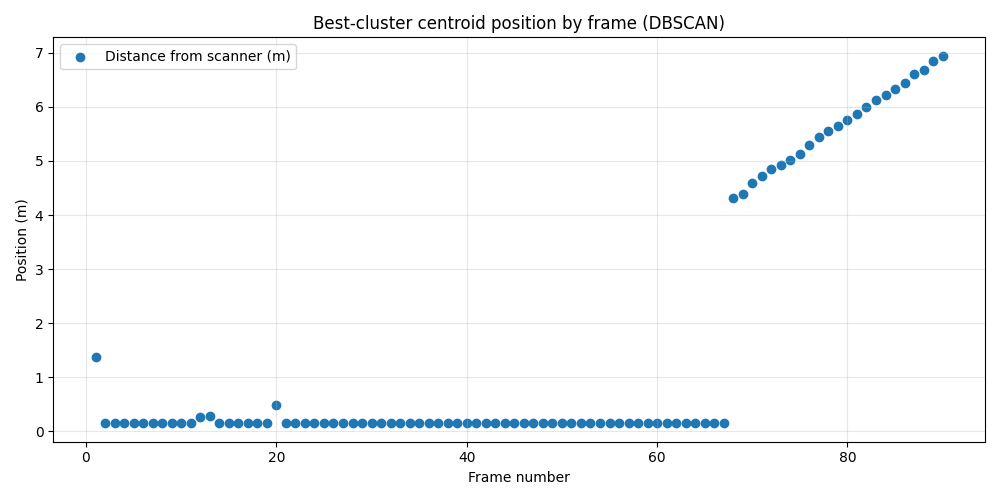

In [19]:
plot_centroid_by_frame()

# Object matching across frames

In [20]:
import pandas as pd
from scipy.optimize import linear_sum_assignment

match_gate = float(association_gate_widget.value)
if match_gate <= 0:
    raise ValueError("The centroid matching gate must be positive.")

previous_objects = {}  # Object ID -> centroid from the preceding frame
next_object_id = 1
object_cluster_rows = []

for frame_number, frame in enumerate(frames, start=1):

    points_for_clustering = prepare_frame_points(
        frame,
        min_distance=min_distance_widget.value,
        max_distance=max_distance_widget.value,
        keep_fraction=keep_fraction_widget.value,
    )

    if not len(points_for_clustering):
        previous_objects = {}
        continue

    labels = cluster_points(
        points_for_clustering,
        method_widget.value,
        cluster_count_widget.value,
        dbscan_eps_widget.value,
        min_samples_widget.value,
        hdbscan_min_cluster_size_widget.value,
        spectral_neighbors_widget.value,
    )

    # Ignore DBSCAN/HDBSCAN noise; each remaining cluster represents an object
    cluster_centroids = {
        int(label): points_for_clustering[labels == label].mean(axis=0)
        for label in np.unique(labels)
        if label != -1
    }

    previous_ids = list(previous_objects)
    current_labels = list(cluster_centroids)
    matched_labels = {}

    if previous_ids and current_labels:
        distances = np.array([
            [
                np.linalg.norm(previous_objects[object_id] - cluster_centroids[label])
                for label in current_labels
            ]
            for object_id in previous_ids
        ])
        previous_indices, current_indices = linear_sum_assignment(distances)

        for previous_index, current_index in zip(previous_indices, current_indices):
            if distances[previous_index, current_index] <= match_gate:
                matched_labels[current_labels[current_index]] = previous_ids[previous_index]

    current_objects = {}
    for label in current_labels:
        if label not in matched_labels:
            matched_labels[label] = next_object_id
            next_object_id += 1

        object_id = matched_labels[label]
        centroid = cluster_centroids[label]
        current_objects[object_id] = centroid

        object_cluster_rows.append({
            "Object ID": object_id,
            "Frame": frame_number,
            "Cluster label": label,
            "Centroid X (m)": centroid[0],
            "Centroid Y (m)": centroid[1],
            "Centroid Z (m)": centroid[2],
        })

    previous_objects = current_objects

object_clusters_df = pd.DataFrame(object_cluster_rows)

print(f"Tracked objects: {object_clusters_df['Object ID'].nunique() if not object_clusters_df.empty else 0}")
display(object_clusters_df)

# Compact per-object listing: each entry maps a frame number to its cluster label.
object_cluster_listing = (
    object_clusters_df.groupby("Object ID")
    .apply(lambda group: dict(zip(group["Frame"], group["Cluster label"])))
    .to_dict()
)
display(object_cluster_listing)

Tracked objects: 1384


,Object ID,Frame,Cluster label,Centroid X (m),Centroid Y (m),Centroid Z (m)
0,1,1,0,0.818372,-0.194195,1.100120
1,2,1,1,2.016551,-1.412104,2.566224
2,3,1,2,2.303266,-1.831203,2.028786
3,4,1,3,2.693984,-2.022099,2.386871
4,5,1,4,1.860635,-1.311706,0.144858
...,...,...,...,...,...,...
6572,1258,90,74,-1.636027,1.876999,0.067147
6573,1282,90,75,-4.049473,2.749915,-0.019480
6574,1297,90,76,-1.838998,2.751427,-0.147041
6575,917,90,77,-1.306437,2.027094,-0.176053


{1: {1: 0,
  2: 2,
  3: 2,
  4: 2,
  5: 2,
  6: 2,
  7: 2,
  8: 2,
  9: 2,
  10: 2,
  11: 2,
  12: 2,
  13: 2,
  14: 3,
  15: 3,
  16: 3,
  17: 3,
  18: 3,
  19: 3,
  20: 2,
  21: 2,
  22: 2,
  23: 2,
  24: 2,
  25: 2,
  26: 2,
  27: 2,
  28: 2,
  29: 2,
  30: 2,
  31: 2,
  32: 2,
  33: 2,
  34: 2},
 2: {1: 1,
  2: 15,
  3: 15,
  4: 18,
  5: 7,
  6: 6,
  7: 8,
  8: 8,
  9: 6,
  10: 9,
  11: 8,
  12: 7,
  13: 8,
  14: 8,
  15: 8,
  16: 8,
  17: 10,
  18: 10,
  19: 8,
  20: 7,
  21: 9,
  22: 10,
  23: 8,
  24: 8,
  25: 8,
  26: 7,
  27: 8,
  28: 10,
  29: 9,
  30: 8,
  31: 5,
  32: 9,
  33: 10,
  34: 8,
  35: 8,
  36: 8,
  37: 8,
  38: 9,
  39: 7,
  40: 6,
  41: 6,
  42: 6,
  43: 9,
  44: 8,
  45: 8,
  46: 7,
  47: 16,
  48: 17,
  49: 8,
  50: 24,
  51: 22,
  52: 19,
  53: 9,
  54: 10,
  55: 11,
  56: 9,
  57: 10,
  58: 9,
  59: 10,
  60: 8,
  61: 10,
  62: 7,
  63: 8,
  64: 6,
  65: 8,
  66: 8,
  67: 8,
  68: 7,
  69: 7,
  70: 8,
  71: 9},
 3: {1: 2, 2: 8, 3: 5, 4: 8, 5: 11},
 4: {1: 3,

# Plot the centroids of all objects 

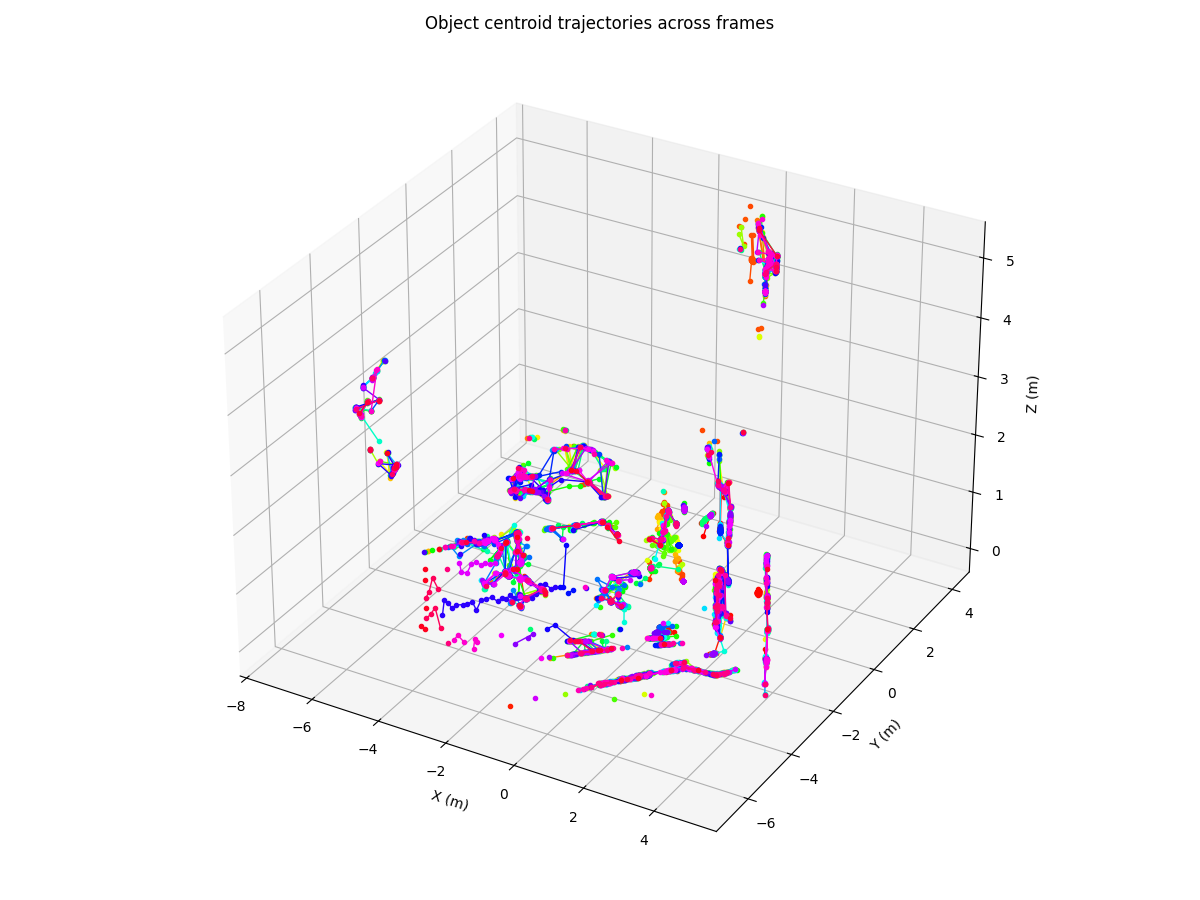

In [21]:
if object_clusters_df.empty:
    print("No object centroids to plot.")
else:
    object_ids = sorted(object_clusters_df["Object ID"].unique())
    colors = plt.get_cmap("hsv")(np.linspace(0, 1, len(object_ids), endpoint=False))

    figure = plt.figure(figsize=(12, 9))
    axes = figure.add_subplot(111, projection="3d")

    for object_id, color in zip(object_ids, colors):
        track = object_clusters_df[
            object_clusters_df["Object ID"] == object_id
        ].sort_values("Frame")

        axes.plot(
            track["Centroid X (m)"],
            track["Centroid Y (m)"],
            track["Centroid Z (m)"],
            marker="o",
            markersize=3,
            linewidth=1,
            color=color,
            label=f"Object {object_id}",
        )

    axes.set_title("Object centroid trajectories across frames")
    axes.set_xlabel("X (m)")
    axes.set_ylabel("Y (m)")
    axes.set_zlabel("Z (m)")

    plt.tight_layout()
    plt.show()

## Count the average number of points in each frame of the recording

In [22]:
frame_point_counts = []

for frame_number, frame in enumerate(frames, start=1):
    filtered_points = prepare_frame_points(
        frame,
        min_distance=min_distance_widget.value,
        max_distance=max_distance_widget.value,
        keep_fraction=keep_fraction_widget.value,
    )

    frame_point_counts.append({
        "Frame": frame_number,
        "Before filtering": len(frame),

    })

frame_point_counts_df = pd.DataFrame(frame_point_counts)
display(frame_point_counts_df.mean(numeric_only=True).to_frame("Average points per frame").round(1))

,Average points per frame
Frame,45.5
Before filtering,101113.6
